# Are there "pure pixel" precincts?

In hyperspectral unmixing a **pure pixel** contains a single material. Some endmember
extractors (VCA, N-FINDR) assume such pixels exist and pick them as the archetypes;
MVSA does not, and lets the simplex vertices lie outside the data. Here the analogue is
a clustered precinct whose voters **all voted for (nearly) the same 12 senators**.
A looser version is a precinct whose votes stay within a pool of 15–18 candidates.

Measures, per clustered precinct with votes $v_1 \ge v_2 \ge \dots$ (sorted, all
candidates) and $T = \sum_i v_i$ senatorial votes in total:

- **Top-k share** $s_k = \sum_{i \le k} v_i \,/\, T$: the share of the precinct's votes
  that went to its own k most-voted candidates. $s_{12} = 1$ means no vote went outside
  some 12-candidate set (strict definition); $s_{15}$, $s_{18}$ are the loose ones.
  It needs no ballot counts, so it works for every year.
- **Identical-ballot bound** (2019+, which report valid ballots $B$): with
  $f_i = v_i / B$ the share of ballots naming candidate $i$,
  $$\ell_{12} = 1 - \sum_{i \le 12} (1 - f_i)$$
  is a guaranteed lower bound on the share of ballots that name **all** of the
  precinct's top 12 (union bound). A ballot holds at most 12 names, so those ballots
  are identical. $\ell_{12} \ge 0.5$ means at least half the voters cast the same ballot.
- **Chance baseline.** Small or homogeneous precincts can look concentrated by chance.
  For each precinct we draw $T$ votes from the national, and separately from its
  province's, candidate shares (a multinomial: one draw per precinct) and recompute
  $s_k$. That is what the precinct would look like if its voters were a random sample
  of the country / province. It ignores ballot structure (votes are not independent
  within a ballot), so it is a "no local clustering" reference, not an exact test.

Precincts with fewer than `MIN_VOTES` total votes are left out of the purity counts.

In [1]:
import sys
from collections import Counter

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import REPO_ROOT, load_config, method_path
from src.data import load_complete
from src.data.preprocessing import preprocess, preprocess_from_config

sns.set_style("whitegrid")

YEARS = ["2013", "2016", "2019", "2022", "2025"]
CONFIGS = {y: load_config(REPO_ROOT / "configs" / f"config_{y}.ini") for y in YEARS}
KS = [12, 15, 18]  # strict (a full ballot) and loose candidate pools
TAU = 0.95  # purity threshold on the top-k share
MIN_VOTES = 600  # ~80 voters at the typical ~7.5 votes per ballot
SEED = 0  # chance-baseline draws
BALLOTS = "information.numberOfValidBallot"


## Load and score every precinct

All candidates are kept (the pipeline's 25th-percentile candidate filter is switched
off), so votes for minor candidates count against purity. The other preprocessing
settings (excluded regions, minimum precinct votes) follow each year's config. The
MVSA and NMF abundances of each precinct are attached for the last section; they come
from the pipeline's own precinct set, so a few precincts may lack them.

In [2]:
def topk_shares(V, ks):
    # (N, K) votes -> {k: (N,) share of each row's total in its k largest entries}
    s = np.cumsum(-np.sort(-V, axis=1), axis=1)
    total = s[:, -1]
    return {k: s[:, k - 1] / total for k in ks}


def group_shares(V, groups):
    # each row's candidate shares within its group (e.g. province), row-aligned
    codes, _ = pd.factorize(groups)
    sums = np.zeros((codes.max() + 1, V.shape[1]))
    np.add.at(sums, codes, V)
    return (sums / sums.sum(axis=1, keepdims=True))[codes]


def load_year(year, rng):
    cfg = CONFIGS[year]
    sec = cfg["preprocessing"]
    df = load_complete(cfg)
    excluded = [r.strip() for r in sec["excluded_regions"].split(",") if r.strip()]
    pre = preprocess(
        df,
        excluded_regions=excluded,
        sen_col_start=sec.getint("sen_col_start"),
        min_candidate_25th_percentile=-np.inf,  # keep every candidate
        min_precinct_votes=sec.getfloat("min_precinct_votes"),
        normalization="none",
        verbose=False,
    )
    V = pre.Y_raw.T  # (N precincts, K candidates), candidates in national-rank order
    T = V.sum(axis=1)
    prec = pre.df_geo[["REGION", "PROVINCE", "CITY_MUNICIPALITY", "BARANGAY"]].copy()
    prec["T"] = T
    prec["B"] = pre.df_geo[BALLOTS].to_numpy(float) if BALLOTS in pre.df_geo else np.nan
    for k, s in topk_shares(V, KS).items():
        prec[f"s{k}"] = s

    # chance baselines: T votes drawn from the national / provincial candidate shares
    T_int = T.astype(np.int64)
    national = np.broadcast_to(V.sum(axis=0) / V.sum(), V.shape)
    province = group_shares(V, prec["REGION"] + "|" + prec["PROVINCE"])
    for name, P in [("nat", national), ("prov", province)]:
        for k, s in topk_shares(rng.multinomial(T_int, P), KS).items():
            prec[f"null_{name}_s{k}"] = s

    # identical-ballot lower bound (needs valid-ballot counts)
    top = -np.sort(-V, axis=1)[:, :12]
    prec["l12"] = 1 - (1 - top / prec["B"].to_numpy()[:, None]).sum(axis=1)

    # each precinct's top-12 slate (candidate indices into `labels`)
    order = np.argsort(-V, axis=1, kind="stable")[:, :12]
    prec["slate"] = [frozenset(r) for r in order]

    # the whole municipality's own top-12 share (is purity town-wide?)
    muni = prec["REGION"] + "|" + prec["PROVINCE"] + "|" + prec["CITY_MUNICIPALITY"]
    codes, _ = pd.factorize(muni)
    sums = np.zeros((codes.max() + 1, V.shape[1]))
    np.add.at(sums, codes, V)
    prec["muni_s12"] = topk_shares(sums, [12])[12][codes]

    # MVSA / NMF abundances, matched through the original table's row labels
    ids = pd.Index(pre.params["precinct_ids"])
    pipe_ids = preprocess_from_config(df, cfg, verbose=False).params["precinct_ids"]
    for method in ["mvsa", "nmf"]:
        path = method_path(cfg, method, "abundances.parquet")
        if not path.exists():
            continue
        ab = pd.read_parquet(path)
        arch = ab.filter(like="arch_")
        arch.index = pipe_ids
        arch = arch.reindex(ids)
        prec[f"max_ab_{method}"] = arch.max(axis=1).to_numpy()
        has = arch.notna().all(axis=1)  # precincts outside the pipeline's set: NaN
        prec[f"dom_{method}"] = arch[has].idxmax(axis=1).reindex(arch.index).to_numpy()

    prec["year"] = year
    return prec, pre.candidate_labels


rng = np.random.default_rng(SEED)
DATA, LABELS = {}, {}
for y in YEARS:
    DATA[y], LABELS[y] = load_year(y, rng)
    p = DATA[y]
    print(
        f"{y}: {len(p):,} precincts, {len(LABELS[y])} candidates, median {p['T'].median():.0f} votes"
        + (f", {np.nanmedian(p['T'] / p['B']):.2f} votes/ballot" if p["B"].notna().any() else "")
    )

2013: 59,679 precincts, 33 candidates, median 4074 votes


2016: 22,986 precincts, 50 candidates, median 3927 votes


2019: 85,114 precincts, 61 candidates, median 4283 votes, 7.64 votes/ballot


2022: 105,033 precincts, 64 candidates, median 4050 votes, 7.71 votes/ballot


2025: 92,486 precincts, 66 candidates, median 4642 votes, 6.69 votes/ballot


## 1. How concentrated are precinct votes, and is the tail more than chance?

Observed top-k shares (filled) against the two chance baselines (lines), log scale to
show the tail. The vertical line marks `TAU`.

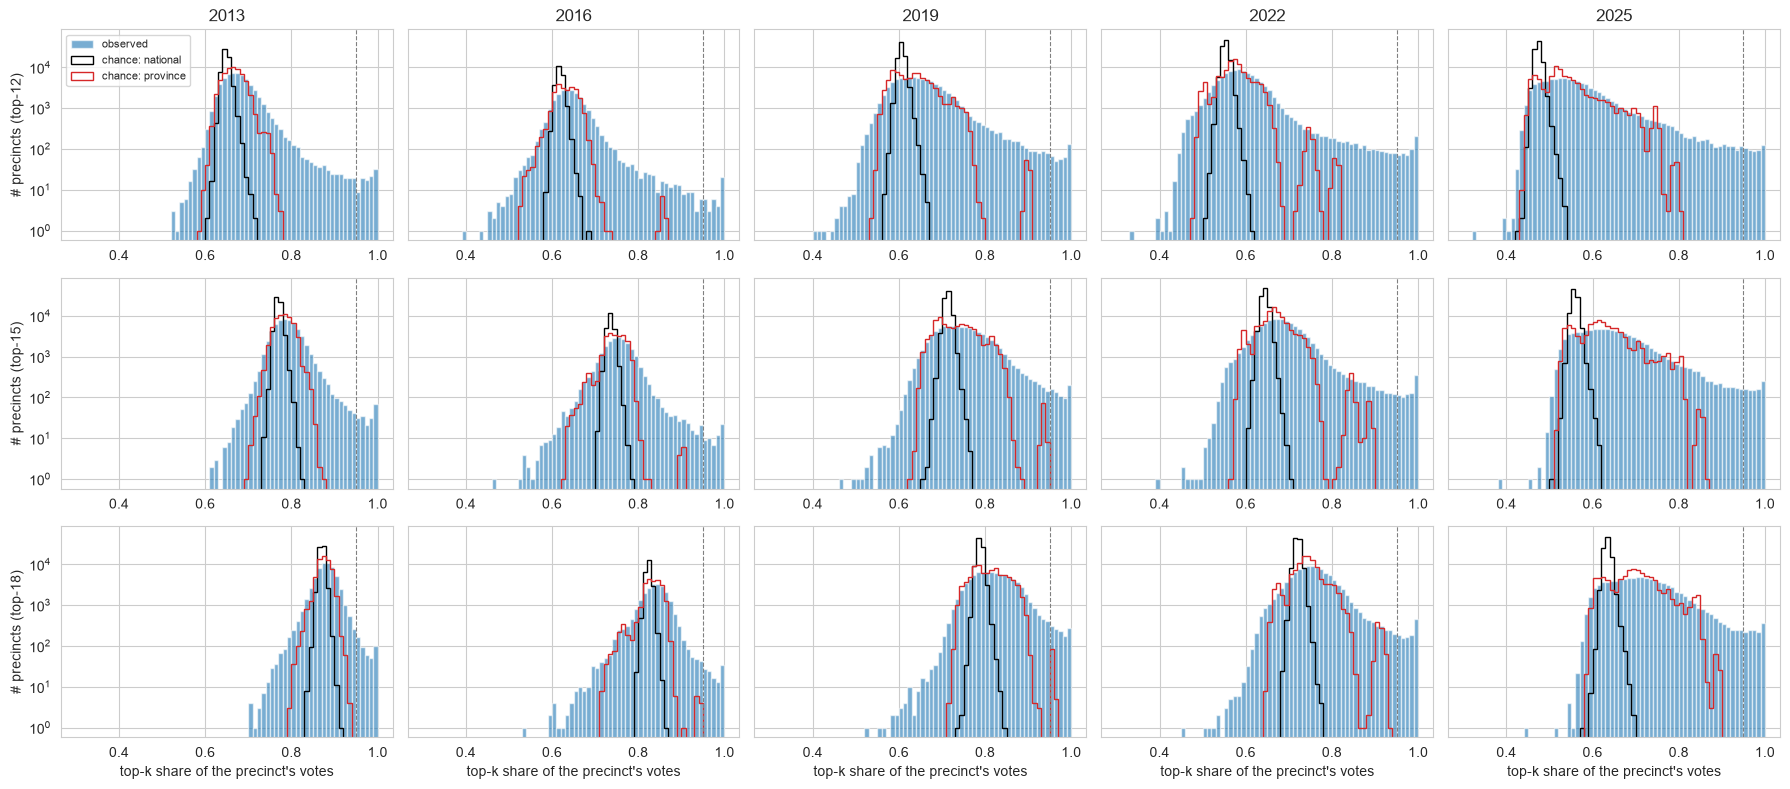

In [3]:
fig, axes = plt.subplots(len(KS), len(YEARS), figsize=(18, 8), sharex="row", sharey=True)
bins = np.linspace(0.3, 1.0, 71)
for j, y in enumerate(YEARS):
    p = DATA[y][DATA[y]["T"] >= MIN_VOTES]
    for i, k in enumerate(KS):
        ax = axes[i, j]
        ax.hist(p[f"s{k}"], bins=bins, color="C0", alpha=0.6, label="observed")
        ax.hist(p[f"null_nat_s{k}"], bins=bins, histtype="step", color="k", label="chance: national")
        ax.hist(p[f"null_prov_s{k}"], bins=bins, histtype="step", color="C3", label="chance: province")
        ax.axvline(TAU, color="grey", ls="--", lw=0.8)
        ax.set_yscale("log")
        if i == 0:
            ax.set_title(y)
        if j == 0:
            ax.set_ylabel(f"# precincts (top-{k})")
        if i == len(KS) - 1:
            ax.set_xlabel("top-k share of the precinct's votes")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()

## 2. How many pure precincts, and how sensitive is that to the threshold?

Share of precincts (≥ `MIN_VOTES` votes) whose top-k share reaches a threshold τ,
for τ from 0.80 to 1.00. The table gives counts at `TAU` against the chance baselines.

,precincts,top-12 ≥ 0.95,chance nat. (top-12),chance prov. (top-12),top-15 ≥ 0.95,chance nat. (top-15),chance prov. (top-15),top-18 ≥ 0.95,chance nat. (top-18),chance prov. (top-18)
year,,,,,,,,,,
2013,58876,101,0,0,186,0,0,467,0,0
2016,22869,40,0,0,61,0,0,117,0,0
2019,84359,374,0,0,701,0,0,1265,0,89
2022,104586,527,0,0,822,0,0,1147,0,0
2025,92199,507,0,0,892,0,0,1300,0,0


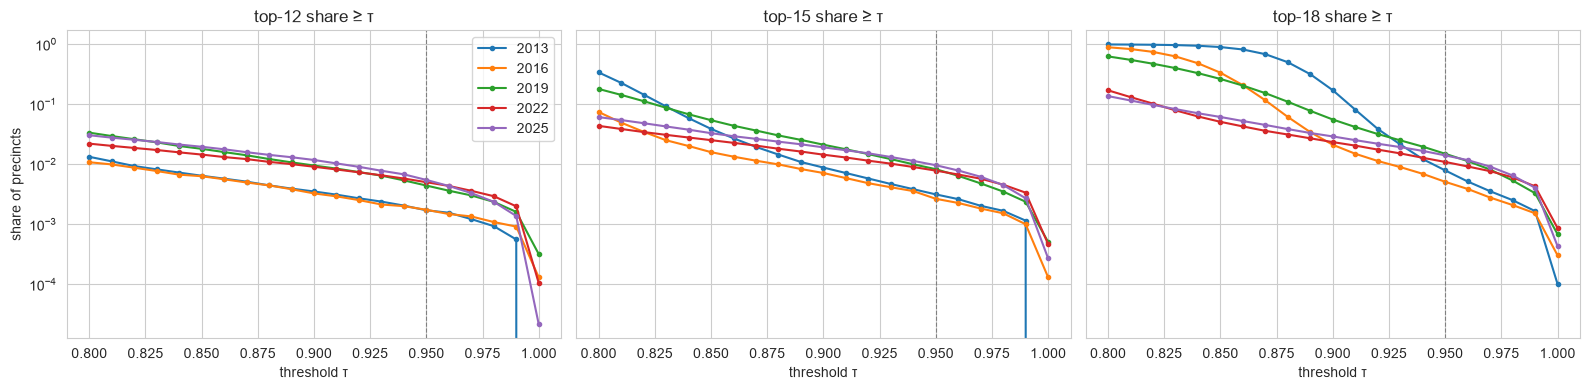

In [4]:
taus = np.round(np.arange(0.80, 1.0001, 0.01), 2)
fig, axes = plt.subplots(1, len(KS), figsize=(16, 4), sharey=True)
for ax, k in zip(axes, KS):
    for y in YEARS:
        s = DATA[y].loc[DATA[y]["T"] >= MIN_VOTES, f"s{k}"].to_numpy()
        ax.plot(taus, [(s >= t).mean() for t in taus], marker=".", label=y)
    ax.axvline(TAU, color="grey", ls="--", lw=0.8)
    ax.set(yscale="log", xlabel="threshold τ", title=f"top-{k} share ≥ τ")
axes[0].set_ylabel("share of precincts")
axes[0].legend()
plt.tight_layout()

rows = []
for y in YEARS:
    p = DATA[y][DATA[y]["T"] >= MIN_VOTES]
    row = {"year": y, "precincts": len(p)}
    for k in KS:
        row[f"top-{k} ≥ {TAU}"] = int((p[f"s{k}"] >= TAU).sum())
        row[f"chance nat. (top-{k})"] = int((p[f"null_nat_s{k}"] >= TAU).sum())
        row[f"chance prov. (top-{k})"] = int((p[f"null_prov_s{k}"] >= TAU).sum())
    rows.append(row)
pd.DataFrame(rows).set_index("year")

## 3. Is it just small precincts?

Top-12 share against precinct size. Chance concentration shrinks as the number of
votes grows, so pure precincts that are also large are hard to explain by sampling noise.

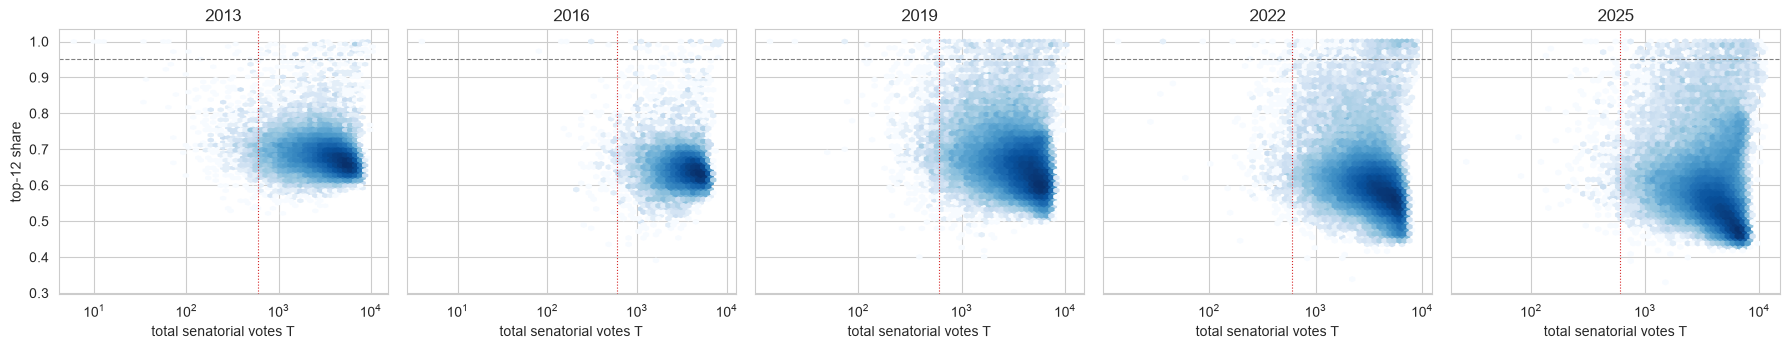

In [5]:
fig, axes = plt.subplots(1, len(YEARS), figsize=(18, 3.6), sharey=True)
for ax, y in zip(axes, YEARS):
    p = DATA[y]
    ax.hexbin(p["T"], p["s12"], gridsize=60, bins="log", cmap="Blues", xscale="log", mincnt=1)
    ax.axhline(TAU, color="grey", ls="--", lw=0.8)
    ax.axvline(MIN_VOTES, color="C3", ls=":", lw=0.8)
    ax.set(title=y, xlabel="total senatorial votes T")
axes[0].set_ylabel("top-12 share")
plt.tight_layout()

## 4. Identical ballots (2019, 2022, 2025)

The lower bound $\ell_{12}$ on the share of ballots naming all of the precinct's top
12. Large values are direct evidence of slate voting: most voters handed in the same
ballot. It is only a bound (it can be ≤ 0 even when many ballots match), so the counts
below are conservative.

,2019,2022,2025
l12 ≥ 0.5,43,125,10
l12 ≥ 0.8,8,38,1
l12 ≥ 0.9,0,7,0


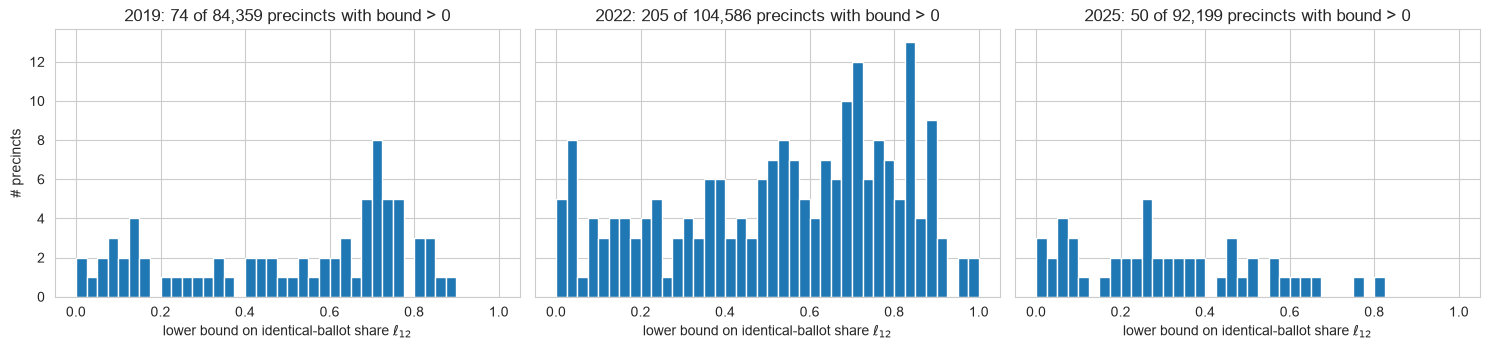

In [6]:
bal_years = [y for y in YEARS if DATA[y]["B"].notna().any()]
fig, axes = plt.subplots(1, len(bal_years), figsize=(5 * len(bal_years), 3.6), sharey=True)
for ax, y in zip(np.atleast_1d(axes), bal_years):
    p = DATA[y][DATA[y]["T"] >= MIN_VOTES]
    # the bound is only informative above 0 (most precincts sit far below it)
    ax.hist(p["l12"], bins=np.linspace(0, 1, 41), color="C0")
    ax.set(
        title=f"{y}: {(p['l12'] > 0).sum()} of {len(p):,} precincts with bound > 0",
        xlabel=r"lower bound on identical-ballot share $\ell_{12}$",
    )
np.atleast_1d(axes)[0].set_ylabel("# precincts")
plt.tight_layout()

pd.DataFrame(
    {
        y: {
            f"l12 ≥ {t}": int((DATA[y].loc[DATA[y]["T"] >= MIN_VOTES, "l12"] >= t).sum())
            for t in (0.5, 0.8, 0.9)
        }
        for y in bal_years
    }
)

## 5. Where are the pure precincts?

Pure here means top-12 share ≥ `TAU` and at least `MIN_VOTES` votes. Provinces ranked
by the number of pure precincts, with the share of the province's precincts that are
pure, and whether the bloc is **town-wide** (the precinct's municipality, pooled, also
has top-12 share ≥ `TAU`).

In [7]:
def pure(y, k=12, tau=TAU):
    p = DATA[y]
    return p[(p["T"] >= MIN_VOTES) & (p[f"s{k}"] >= tau)]


tables = []
for y in YEARS:
    p = DATA[y][DATA[y]["T"] >= MIN_VOTES]
    pu = pure(y)
    g = pu.groupby(["REGION", "PROVINCE"]).agg(
        pure=("s12", "size"), town_wide=("muni_s12", lambda s: (s >= TAU).mean())
    )
    g["share_of_province"] = g["pure"] / p.groupby(["REGION", "PROVINCE"]).size().reindex(g.index)
    g["year"] = y
    tables.append(g.sort_values("pure", ascending=False).head(8))
    print(
        f"{y}: {len(pu)} pure precincts in {pu['PROVINCE'].nunique()} provinces / "
        f"{pu['CITY_MUNICIPALITY'].nunique()} municipalities; "
        f"{(pu['muni_s12'] >= TAU).mean():.0%} in town-wide blocs; by region: "
        + ", ".join(f"{r} {n}" for r, n in pu["REGION"].value_counts().head(4).items())
    )
pd.concat(tables).reset_index().set_index(["year", "REGION", "PROVINCE"]).round(3)

2013: 101 pure precincts in 18 provinces / 33 municipalities; 1% in town-wide blocs; by region: ARMM 40, REGION X 29, REGION IV-A 9, NCR 7
2016: 40 pure precincts in 16 provinces / 22 municipalities; 10% in town-wide blocs; by region: ARMM 11, REGION X 9, PLACEHOLDER 6, REGION III 4
2019: 374 pure precincts in 25 provinces / 88 municipalities; 26% in town-wide blocs; by region: BARMM 265, REGION X 56, REGION VIII 11, NCR 11
2022: 527 pure precincts in 19 provinces / 79 municipalities; 29% in town-wide blocs; by region: BARMM 363, REGION X 71, REGION XII 27, REGION VIII 26
2025: 507 pure precincts in 24 provinces / 107 municipalities; 16% in town-wide blocs; by region: BARMM 172, REGION VIII 93, REGION X 92, REGION IX 84


pure  town_wide  \
year REGION      PROVINCE                                                     
2013 REGION X    LANAO DEL NORTE                              26      0.000   
     ARMM        SULU                                         23      0.000   
                 MAGUINDANAO                                  11      0.091   
     NCR         NATIONAL CAPITAL REGION - SECOND DISTRICT     7      0.000   
     REGION IV-A RIZAL                                         6      0.000   
     REGION III  NUEVA ECIJA                                   4      0.000   
     REGION IV-A CAVITE                                        3      0.000   
     REGION X    MISAMIS OCCIDENTAL                            3      0.000   
2016 ARMM        SULU                                          7      0.286   
     REGION X    LANAO DEL NORTE                               7      0.000   
     PLACEHOLDER PLACEHOLDER                                   6      0.000   
     REGION III  NUEVA ECIJA                                   3      0.000   
     REGION IV-A CAVITE                                        3      0.000   
     ARMM        MAGUINDANAO                                   2      0.500   
                 TAWI-TAWI                                     2      0.000   
     REGION X    MISAMIS OCCIDENTAL                            2      0.000   
2019 BARMM       MAGUINDANAO                                 105      0.286   
                 SULU                                         89      0.517   
     REGION X    LANAO DEL NORTE                              41      0.512   
     BARMM       LANAO DEL SUR                                39      0.026   
                 TAWI-TAWI                                    25      0.000   
     NCR         NATIONAL CAPITAL REGION - SECOND DISTRICT    11      0.000   
     REGION X    MISAMIS OCCIDENTAL                            8      0.000   
     BARMM       BASILAN                                       7      0.000   
2022 BARMM       SULU                                        206      0.515   
     REGION X    LANAO DEL NORTE                              71      0.296   
     BARMM       LANAO DEL SUR                                58      0.224   
                 MAGUINDANAO                                  57      0.193   
                 TAWI-TAWI                                    28      0.000   
     REGION XII  SULTAN KUDARAT                               23      0.000   
     BARMM       BASILAN                                      14      0.000   
     NCR         NCR - SECOND DISTRICT                        14      0.000   
2025 REGION VIII SAMAR                                        88      0.000   
     REGION IX   SULU                                         80      0.100   
     REGION X    LANAO DEL NORTE                              60      0.350   
     BARMM       LANAO DEL SUR                                50      0.000   
                 MAGUINDANAO DEL SUR                          37      0.000   
                 BASILAN                                      33      0.364   
     REGION X    MISAMIS OCCIDENTAL                           32      0.000   
     BARMM       TAWI-TAWI                                    30      0.767   

                                                            share_of_province  
year REGION      PROVINCE                                                      
2013 REGION X    LANAO DEL NORTE                                        0.060  
     ARMM        SULU                                                   0.131  
                 MAGUINDANAO                                            0.035  
     NCR         NATIONAL CAPITAL REGION - SECOND DISTRICT              0.003  
     REGION IV-A RIZAL                                                  0.004  
     REGION III  NUEVA ECIJA                                            0.003  
     REGION IV-A CAVITE                                                 0.002  
     REGION X    MISA

## 6. What did they vote for?

The top-12 **slate** of each pure precinct (its 12 most-voted candidates, as a set).
Do pure precincts share a few common slates, and how do those compare with the
national winners (national top 12)?

In [8]:
def jaccard(a, b):
    return len(a & b) / len(a | b)


summary = []
for y in YEARS:
    pu = pure(y)
    if pu.empty:
        continue
    labels = LABELS[y]
    winners = frozenset(range(12))  # candidates are in national-rank order
    counts = Counter(pu["slate"])
    modal, n_modal = counts.most_common(1)[0]
    summary.append(
        {
            "year": y,
            "pure precincts": len(pu),
            "distinct slates": len(counts),
            "precincts on modal slate": n_modal,
            "mean Jaccard to modal slate": np.mean([jaccard(s, modal) for s in pu["slate"]]),
            "mean Jaccard to national top 12": np.mean([jaccard(s, winners) for s in pu["slate"]]),
        }
    )
    print(f"\n{y}: three most common slates among {len(pu)} pure precincts")
    for slate, n in counts.most_common(3):
        where = pu.loc[pu["slate"] == slate, "PROVINCE"].value_counts().head(3)
        names = [labels[i] for i in sorted(slate)]
        print(
            f"  {n:4d} precincts ({', '.join(f'{pr} {c}' for pr, c in where.items())}); "
            f"{len(slate & winners)}/12 national winners:\n    " + "; ".join(names)
        )
pd.DataFrame(summary).set_index("year").round(3)


2013: three most common slates among 101 pure precincts
    25 precincts (NATIONAL CAPITAL REGION - SECOND DISTRICT 7, RIZAL 6, NUEVA ECIJA 4); 10/12 national winners:
    POE, GRACE [1]; LEGARDA, LOREN (NPC) [2]; CAYETANO, ALAN PETER (NP) [4]; BINAY, NANCY (UNA) [5]; ANGARA, EDGARDO (LDP) [6]; AQUINO, BENIGNO BAM (LP) [7]; TRILLANES, ANTONIO IV (NP) [9]; VILLAR, CYNTHIA HANEPBUHAY (NP) [10]; EJERCITO ESTRADA, JV (UNA) [11]; HONASAN, GRINGO (UNA) [12]; GORDON, DICK (UNA) [13]; ENRILE, JUAN PONCE JR.(NPC) [15]
    14 precincts (LANAO DEL NORTE 14); 7/12 national winners:
    POE, GRACE [1]; CAYETANO, ALAN PETER (NP) [4]; ANGARA, EDGARDO (LDP) [6]; AQUINO, BENIGNO BAM (LP) [7]; PIMENTEL, KOKO (PDP) [8]; TRILLANES, ANTONIO IV (NP) [9]; VILLAR, CYNTHIA HANEPBUHAY (NP) [10]; ZUBIRI, MIGZ (UNA) [14]; ENRILE, JUAN PONCE JR.(NPC) [15]; MAGSAYSAY, RAMON JR. (LP) [16]; HONTIVEROS, RISA (AKBAYAN) [17]; MADRIGAL, JAMBY (LP) [20]
     9 precincts (LANAO DEL NORTE 4, SULU 3, BASILAN 2); 9/12 nation

,pure precincts,distinct slates,precincts on modal slate,mean Jaccard to modal slate,mean Jaccard to national top 12
year,,,,,
2013,101,44,25,0.582,0.548
2016,40,20,16,0.621,0.499
2019,374,246,34,0.553,0.547
2022,527,190,90,0.514,0.412
2025,507,233,82,0.452,0.398


## 7. Do pure precincts sit at the archetypes?

If pure precincts are the "pure pixels" of the unmixing, they should sit near a vertex
of the simplex: one archetype's abundance near 1. Compare the largest abundance of
pure precincts with all the others, for the MVSA and NMF pipeline runs (config p).

pure precincts max abundance ≥ 0.9  \
year method                                       
2013 MVSA               101                  0%   
     NMF                101                 17%   
2016 MVSA                40                  0%   
     NMF                 40                  0%   
2019 MVSA               374                  0%   
     NMF                374                  9%   
2022 MVSA               527                  0%   
     NMF                527                  9%   
2025 MVSA               507                  0%   
     NMF                507                 34%   

                            dominant archetypes  
year method                                      
2013 MVSA       arch_3 40, arch_1 30, arch_2 28  
     NMF        arch_0 40, arch_2 37, arch_1 17  
2016 MVSA        arch_3 19, arch_2 16, arch_0 3  
     NMF         arch_3 16, arch_1 13, arch_2 6  
2019 MVSA      arch_0 134, arch_3 96, arch_4 90  
     NMF      arch_4 209, arch_2 143, arch_0 18  
2022 MVSA     arch_4 212, arch_2 108, arch_3 81  
     NMF      arch_2 288, arch_3 115, arch_5 65  
2025 MVSA     arch_0 229, arch_1 132, arch_4 74  
     NMF     arch_2 183, arch_1 171, arch_5 144

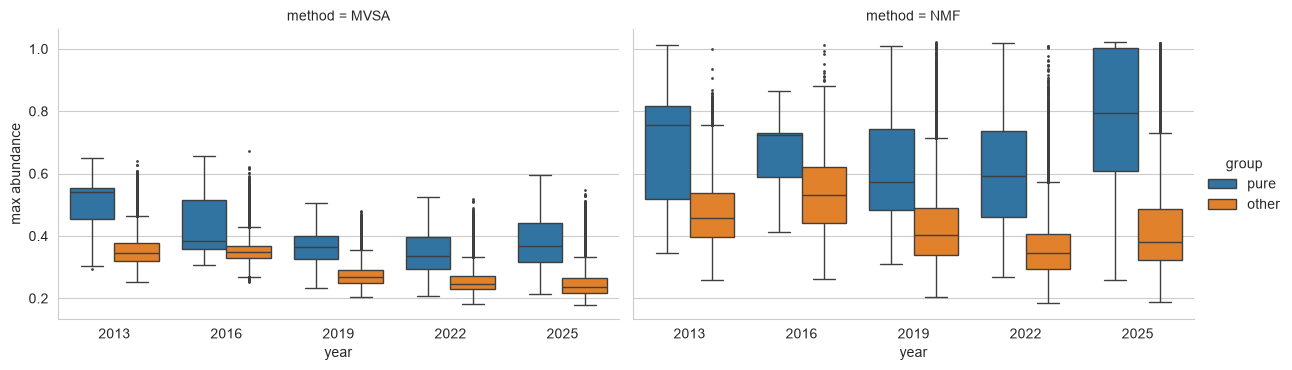

In [9]:
rows = []
for y in YEARS:
    p = DATA[y][DATA[y]["T"] >= MIN_VOTES]
    is_pure = p["s12"] >= TAU
    for method in ["mvsa", "nmf"]:
        col = f"max_ab_{method}"
        if col not in p:
            continue
        for flag, sub in [("pure", p[is_pure]), ("other", p[~is_pure])]:
            rows += [{"year": y, "method": method.upper(), "group": flag, "max abundance": v}
                     for v in sub[col].dropna()]
ab = pd.DataFrame(rows)
g = sns.catplot(data=ab, x="year", y="max abundance", hue="group", col="method",
                kind="box", fliersize=1, height=3.8, aspect=1.6)

rows = []
for y in YEARS:
    pu = pure(y)
    for method in ["mvsa", "nmf"]:
        if f"max_ab_{method}" not in pu:
            continue
        rows.append({
            "year": y, "method": method.upper(), "pure precincts": len(pu),
            "max abundance ≥ 0.9": f"{(pu[f'max_ab_{method}'] >= 0.9).mean():.0%}",
            "dominant archetypes": ", ".join(
                f"{a} {n}" for a, n in pu[f"dom_{method}"].value_counts().head(3).items()),
        })
pd.DataFrame(rows).set_index(["year", "method"])

## Takeaways

Numbers from the run of 2026-10-20 with `TAU = 0.95`, `MIN_VOTES = 600`; rerun the
cells above to refresh them.

- **Pure precincts exist in every year, far beyond chance.** Top-12 share ≥ 0.95:
  101 (2013), 40 (2016), 374 (2019), 527 (2022), 507 (2025) clustered precincts, i.e.
  0.2% of precincts in 2013/2016 rising to about 0.5% from 2019. Neither chance
  baseline (national or provincial) produces any. The loose definitions roughly double
  to triple the counts (top-15: 186 / 61 / 701 / 822 / 892; top-18: 467 / 117 /
  1265 / 1147 / 1300). Top-18 discriminates less in 2013, which had only 33 candidates.
  2016 is a partial dataset (about 23k precincts), so compare shares, not counts.
- **They are not small-precinct noise.** Pure precincts span the full size range, up
  to about 10⁴ votes (section 3).
- **Many are literally identical ballots.** In 2019 / 2022 / 2025, at least half the
  ballots in 43 / 125 / 10 precincts named the same 12 candidates, and at least 80% in
  8 / 38 / 1. This is a conservative bound.
- **Geographically concentrated.** Every year: Sulu, Maguindanao, Lanao del Sur,
  Tawi-Tawi and Basilan (ARMM/BARMM), plus Lanao del Norte (Region X). BARMM holds 265
  of 374 in 2019 and 363 of 527 in 2022. In 2025 they spread out: Samar has 88, almost
  all on a single slate, and Sulu is listed under Region IX that year. Mostly these are
  blocs of individual precincts, not whole towns: only 1–29% sit in a municipality
  whose pooled votes are also pure (more in Sulu and Tawi-Tawi).
- **Local slates, not one national slate.** Pure precincts use 20–246 distinct slates,
  but a few local ones dominate: Sulu (34 precincts in 2019, 90 in 2022), Samar (82 in
  2025), and Lanao del Norte every year, often with several non-winning candidates.
  One slate recurs in 2013–2022 across NCR's second district, Rizal, Cavite and Nueva
  Ecija. It is close to the national winners (10–11 of 12), which suggests a centrally
  endorsed bloc vote. Comparing it with published endorsement lists (e.g. Iglesia ni
  Cristo's) is worth doing; it is not checked here.
- **Pure precincts are not where the archetypes sit.** They have higher maximum
  abundance than other precincts, but none reaches 0.9 under MVSA (medians around
  0.35–0.55). That is consistent with MVSA placing its vertices outside the data. NMF
  puts more of them near a vertex: 0–34% reach 0.9, most in 2025. So in the
  unmixing sense, the data does not supply pure pixels for the archetypes. Pure
  precincts are rare (under 1%) and split across many local slates, each covering only
  tens of precincts — too few to become one of p = 4–7 archetypes. That fits the
  choice of MVSA, which does not assume pure pixels, over VCA/N-FINDR.

Caveats: the chance baseline treats votes as independent (no ballot structure); 2016's
`PLACEHOLDER` region holds precincts without geography; abundances are from the
config-p pipeline runs only.